# GGUF on the Intel GPU: FP16 vs 4-bit

Load two versions of **Qwen3-1.7B** directly with **OpenVINO GenAI**. Compare file size and generation speed. No export, conversion, or install cells.

We use Qwen3 because the released GenAI GGUF loader does not support Qwen3.5 yet. Both files come from [ggml-org](https://huggingface.co/ggml-org/Qwen3-1.7B-GGUF); the floating-point file is FP16, not BF16. Downloads total about **5.4 GB**. Run top to bottom after starting Jupyter with the course launcher.

In [1]:
import gc
from pathlib import Path
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
import openvino as ov
import openvino_genai as genai
from huggingface_hub import hf_hub_download

DEVICE = 'GPU'
core = ov.Core()
print('Device:', core.get_property(DEVICE, 'FULL_DEVICE_NAME'))
assert 'FP16' in core.get_property(DEVICE, 'OPTIMIZATION_CAPABILITIES')

REPO = 'ggml-org/Qwen3-1.7B-GGUF'
REVISION = 'daeb8e2d528a760970442092f6bf1e55c3b659eb'
FILES = {'FP16': 'Qwen3-1.7B-f16.gguf', 'Q4_K_M': 'Qwen3-1.7B-Q4_K_M.gguf'}
TOKENS = 128
REPEATS = 3
QUESTION = 'Explain how quantization makes a language model smaller. Give a simple example.'
# Qwen chat format, with thinking disabled.
PROMPT = f'<|im_start|>user\n{QUESTION}<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'

Device: Intel(R) Graphics (iGPU)


## 1. Download the two files
Downloads are cached; rerunning reuses them.

In [2]:
paths = {label: Path(hf_hub_download(REPO, filename, revision=REVISION))
         for label, filename in FILES.items()}
for label, path in paths.items():
    print(f'{label}: {path.stat().st_size / 2**20:,.0f} MiB')

C:\Users\aiwit\Intro-to-practical-AI-course\7. Performance\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aiwit\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Qwen3-1.7B-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 1.28GB            

Qwen3-1.7B-Q4_K_M.gguf: downloading bytes:           |  0.00B            

FP16: 3,881 MiB
Q4_K_M: 1,223 MiB


C:\Users\aiwit\Intro-to-practical-AI-course\7. Performance\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aiwit\.cache\huggingface\hub\models--ggml-org--Qwen3-1.7B-GGUF. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 2. Load and benchmark on GPU
One model at a time, one warm-up, then three timed runs. Same prompt, greedy decoding, and exactly 128 output tokens (EOS is ignored only for timing). Prefix caching is avoided with the SDPA backend. Compilation is not timed; errors are not retried on CPU.

**Tokens/s** includes the whole generation call: prompt processing, generation and text decoding. File size is not a RAM measurement. Q4_K_M is mixed-precision weight compression, not an all-INT4 computation mode.

In [5]:
config = genai.GenerationConfig()
config.max_new_tokens = TOKENS
config.do_sample = False
config.ignore_eos = True #this is just to make benchmarking work nice, dont actually use this
config.apply_chat_template = False  # Already formatted above.

results, answers = [], {}
for label, path in paths.items():
    print(f'Loading {label} on {DEVICE}...')
    pipe = genai.LLMPipeline(str(path), DEVICE,
                             INFERENCE_PRECISION_HINT='f16')
    try:
        pipe.generate([PROMPT], config)  # Warm-up.
        times = []
        for _ in range(REPEATS):
            start = perf_counter()
            output = pipe.generate([PROMPT], config)
            times.append(perf_counter() - start)
            assert output.perf_metrics.get_num_generated_tokens() == TOKENS
        seconds = median(times)
        results.append({'model': label, 'size_mib': path.stat().st_size / 2**20,
                        'seconds': seconds, 'tokens_per_second': TOKENS / seconds})
        print(f'{label}: {seconds:.2f} s, {TOKENS / seconds:.1f} tokens/s')
        config.ignore_eos = False
        answers[label] = pipe.generate([PROMPT], config).texts[0]
        config.ignore_eos = True
    finally:
        del pipe
        gc.collect()

Loading FP16 on GPU...
FP16: 6.20 s, 20.7 tokens/s
Loading Q4_K_M on GPU...
Q4_K_M: 2.58 s, 49.6 tokens/s


## 3. Compare
Smaller files are better; higher tokens/s is better. Is the compressed model faster on your GPU?

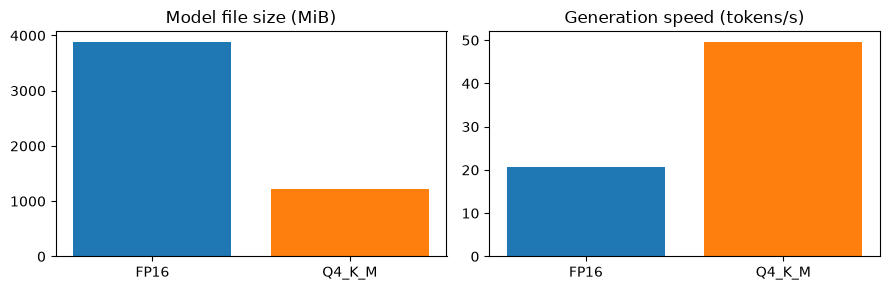

Size reduction: 3.17x
Speed ratio (4-bit / FP16): 2.40x

FP16:
Quantization is a technique used in machine learning to reduce the size and computational requirements of models by approximating the weights and activations with fewer bits. This makes the model smaller and more efficient, especially for deployment on devices with limited resources.

---

### **How Quantization Makes a Language Model Smaller:**

Quantization reduces the number of bits used to represent numbers. Instead of using 32 bits (like in floating-point numbers), you can use fewer bits, such as 8 bits (int8), which significantly reduces the memory and computational overhead.

For example:
- A 32-bit float (like in a neural network)

Q4_K_M:
Quantization is a technique used in machine learning and deep learning to reduce the size and computational complexity of models. In the context of **language models**, quantization makes the model smaller by **reducing the precision of the weights and activations**.

---

### How

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3))
for axis, key, title in zip(axes, ['size_mib', 'tokens_per_second'],
                            ['Model file size (MiB)', 'Generation speed (tokens/s)']):
    axis.bar([r['model'] for r in results], [r[key] for r in results],
             color=['tab:blue', 'tab:orange'])
    axis.set_title(title)
figure.tight_layout()
plt.show()

fp16, q4 = results
print(f'Size reduction: {fp16["size_mib"] / q4["size_mib"]:.2f}x')
print(f'Speed ratio (4-bit / FP16): {q4["tokens_per_second"] / fp16["tokens_per_second"]:.2f}x')
for label, answer in answers.items():
    print(f'\n{label}:\n{answer}')